# Lezione 9 — Dimostrare e discutere: che cosa sappiamo costruire, e che cosa sappiamo criticare?
**Machine Learning for the Humanities · 20 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/09_dimostrare_e_discutere.ipynb)

**Oggi:** presentazioni dei progetti, riflessione collettiva e valutazione finale.

Questo notebook serve a tre cose: organizzare le **presentazioni**, rivedere **tutto il corso su un solo problema**
(che cosa sappiamo costruire), e allenare lo **sguardo critico** con un esperimento che smonta un nostro risultato
(che cosa sappiamo criticare).

### Obiettivi di apprendimento
1. presentare un piccolo progetto con domanda, dati, metodo, risultato e limiti;
2. confrontare i metodi del corso sullo stesso compito;
3. riconoscere i principali errori di metodo (baseline, leakage, confondimenti, generalizzazione, bias);
4. valutare il proprio percorso.

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

def leggi_testo(nome):
    righe = (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines()
    return "\n".join(r for r in righe if not r.startswith("#"))

def brani(testo, n_parole=200):
    """Divide un testo in brani di almeno n_parole, senza spezzare i paragrafi."""
    paragrafi = [" ".join(p.split()) for p in re.split(r"\n\s*\n", testo) if len(p.split()) > 3]
    out, cur = [], []
    for p in paragrafi:
        cur.append(p)
        if sum(len(x.split()) for x in cur) >= n_parole:
            out.append(" ".join(cur)); cur = []
    return out

passaggi = pd.read_csv(DATI / "passaggi_autori.csv")

## 1. Le presentazioni
**Formato:** 7 minuti di presentazione + 5 di discussione per gruppo. Una persona del gruppo successivo fa la prima domanda.

**Struttura consigliata (5–6 slide):**
1. la **domanda** (in una frase) e perché interessa a un umanista;
2. i **dati**: quali testi, quanti, perché quelli;
3. il **metodo** e la **baseline**;
4. il **risultato** principale, con **un** grafico chiaro;
5. i **limiti**: che cosa *non* possiamo concludere;
6. che cosa fareste con più tempo (o con più dati).

**Griglia di valutazione dei progetti**

| Criterio | Che cosa guardiamo | Peso |
|---|---|---|
| Domanda | chiara, motivata, rispondibile con i dati | 20% |
| Dati e metodo | adeguati alla domanda; baseline presente | 25% |
| Risultati | corretti, riproducibili (il notebook gira dall'alto in basso) | 20% |
| Interpretazione critica | limiti, ipotesi alternative, lettura dei testi | 25% |
| Comunicazione | grafici leggibili, tempi rispettati, risposte alle domande | 10% |

## 2. La mappa del corso
| Lezione | Domanda guida | Metodo | Idea chiave |
|---|---|---|---|
| 4/11 | Primo programma | regressione lineare e logistica | prevedere un numero / un sì-no |
| 5/11 | Come trasformare testi in numeri? | albero di decisione | frequenze e caratteristiche; regole leggibili |
| 9/11 | Le macchine scoprono le regole? | SVM | apprendimento supervisionato, TF-IDF |
| 11/11 | Il 95% è buono? | baseline, matrice di confusione | precision, recall; non supervisionato |
| 12/11 | L'AI come assistente | k-means | testare il codice; cluster da interpretare |
| 16/11 | Le macchine capiscono? | clustering gerarchico | similarità del coseno, dendrogrammi |
| 18/11 | Che cosa non comprendono? | semantica distribuzionale | embeddings, ironia, bias |
| 19/11 | Una domanda vera | modelli di lingua | perplessità, memorizzazione, progetto |

## 3. Che cosa sappiamo costruire: tutti i metodi, un solo problema
Il problema: **chi ha scritto questa frase?** (cinque prosatori, frasi singole). Confrontiamo i metodi del corso.

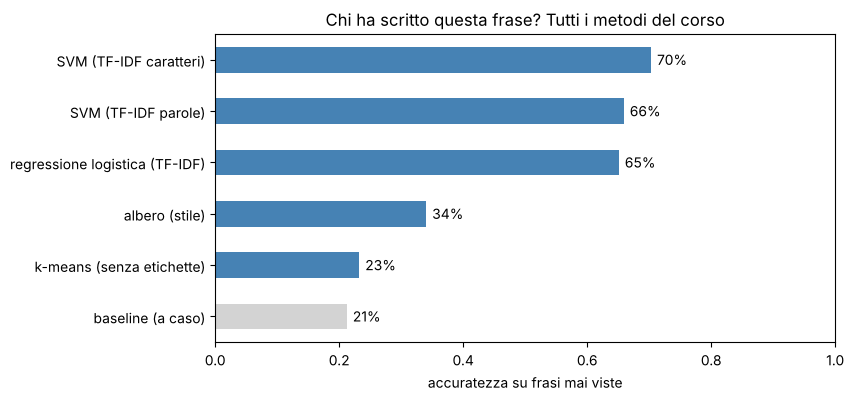

In [3]:
righe = []
for file, autore in {"collodi_pinocchio.txt": "Collodi", "manzoni_promessi_sposi.txt": "Manzoni",
                     "deledda_dopo_il_divorzio.txt": "Deledda", "pirandello_cavallo_nella_luna.txt": "Pirandello",
                     "digiacomo_novelle_napolitane.txt": "Di Giacomo"}.items():
    testo = " ".join(leggi_testo(file).split())
    for f in re.split(r"(?<=[.!?;])\s+", testo):
        if len(f.split()) >= 6:
            righe.append({"autore": autore, "frase": f})
frasi = pd.DataFrame(righe).groupby("autore").sample(600, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(frasi["frase"], frasi["autore"], test_size=0.25,
                                                    random_state=0, stratify=frasi["autore"])

def stile(testi):
    """Le caratteristiche stilistiche della lezione 2, per l'albero di decisione."""
    out = []
    for t in testi:
        n = max(len(t.split()), 1)
        out.append([np.mean([len(w) for w in t.split()]), n, t.count("—") / n, t.count(";") / n,
                    t.count("!") / n, t.count(",") / n, t.count("«") / n])
    return np.array(out)

risultati = {}
risultati["baseline (a caso)"] = DummyClassifier(strategy="stratified", random_state=0).fit(X_train, y_train).score(X_test, y_test)
risultati["albero (stile)"] = DecisionTreeClassifier(max_depth=6, random_state=0).fit(stile(X_train), y_train).score(stile(X_test), y_test)
risultati["regressione logistica (TF-IDF)"] = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000)).fit(X_train, y_train).score(X_test, y_test)
risultati["SVM (TF-IDF parole)"] = make_pipeline(TfidfVectorizer(), LinearSVC()).fit(X_train, y_train).score(X_test, y_test)
risultati["SVM (TF-IDF caratteri)"] = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)), LinearSVC()).fit(X_train, y_train).score(X_test, y_test)

# k-means: non supervisionato. Diamo a ogni cluster l'autore più frequente al suo interno e misuriamo la "purezza".
vett = TfidfVectorizer(min_df=2).fit(X_train)
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(vett.transform(X_train))
nome_cluster = pd.crosstab(km.labels_, y_train.values).idxmax(axis=1)
risultati["k-means (senza etichette)"] = np.mean(nome_cluster[km.predict(vett.transform(X_test))].values == y_test.values)

ris = pd.Series(risultati).sort_values()
ris.plot(kind="barh", color=["lightgray"] + ["steelblue"] * (len(ris) - 1), figsize=(8, 4))
plt.xlabel("accuratezza su frasi mai viste"); plt.xlim(0, 1)
for i, v in enumerate(ris):
    plt.text(v + 0.01, i, f"{v:.0%}", va="center")
plt.title("Chi ha scritto questa frase? Tutti i metodi del corso"); plt.show()

**Che cosa ci dice il grafico.** I metodi supervisionati con TF-IDF battono nettamente la baseline; l'albero con poche caratteristiche
di stile è più debole ma **leggibile**; il k-means, che non ha mai visto un'etichetta, trova gruppi che coincidono poco con gli autori
(cerca *somiglianze*, non *autori*). Nessun metodo "vince" in assoluto: si sceglie in base alla domanda, ai dati e a quanto
bisogna poter **spiegare** il risultato.

## 4. Che cosa sappiamo criticare: autore o libro?
Nella lezione 3 la SVM riconosceva l'autore di un brano di 200 parole quasi al 100%. Ma ogni autore era rappresentato da **un solo libro**.
Mettiamola alla prova: addestriamo sui cinque autori (per Pirandello: le **novelle**) e chiediamo di attribuire i brani di un altro libro
di Pirandello, il **saggio** *L'umorismo*. Se il modello avesse davvero imparato "Pirandello", dovrebbe riconoscerlo.

In [4]:
svm = make_pipeline(TfidfVectorizer(), LinearSVC()).fit(passaggi["testo"], passaggi["autore"])
saggio = brani(leggi_testo("pirandello_umorismo.txt"))
attribuzioni = pd.Series(svm.predict(saggio)).value_counts()
print(f"{len(saggio)} brani del saggio 'L'umorismo' di Pirandello. A chi li attribuisce il modello?\n")
print(attribuzioni.to_string())
print(f"\nRiconosciuti come Pirandello: {attribuzioni.get('Pirandello', 0) / len(saggio):.0%}")

169 brani del saggio 'L'umorismo' di Pirandello. A chi li attribuisce il modello?

Manzoni       104
Pirandello     57
Di Giacomo      5
Deledda         3

Riconosciuti come Pirandello: 34%


**Il modello non ha imparato "Pirandello".** Ha imparato *le novelle di* Pirandello: i loro personaggi, i loro luoghi, il loro
registro narrativo. Davanti a un saggio, cioè a un **genere diverso**, attribuisce la maggior parte dei brani a Manzoni, la voce più
argomentativa e saggistica del training (pensate alle digressioni storiche dei *Promessi sposi*). Il 100% della lezione 3 era vero,
ma rispondeva a una domanda diversa da quella che credevamo: **"da quale di questi cinque libri viene il brano?"**.

È un **confondimento** (*confound*): autore, opera e genere andavano insieme nei dati, e il modello non poteva separarli.
Per studiare davvero l'attribuzione d'autore servono **più opere per autore**, di generi diversi, e un test su opere mai viste.

### Le domande da fare a ogni risultato
1. **Baseline:** rispetto a che cosa è buono questo numero?
2. **Dati di test:** il modello li ha davvero mai visti? C'è una **fuga di informazione** (*leakage*)?
3. **Confondimenti:** che cos'altro varia insieme alla cosa che studio (opera, genere, edizione, epoca)?
4. **Etichette:** chi le ha decise, con quale regola? Sono rumorose?
5. **Rappresentatività:** i miei testi rappresentano ciò di cui voglio parlare?
6. **Generalizzazione:** il risultato regge su testi diversi da quelli di addestramento?
7. **Interpretazione:** il modello ha imparato ciò che credo, o una scorciatoia? (Guardate i pesi, leggete gli errori!)
8. **Bias e conseguenze:** chi è rappresentato nei dati e chi no? Che cosa succede se usiamo questo modello per decidere?

## 5. Riflessione collettiva
Discutiamo in gruppo (e poi tutti insieme):
- Che cosa vi ha sorpreso di più in quello che le macchine **sanno fare**? E in quello che **non** sanno fare?
- In quale momento del corso un numero vi ha **ingannato**, e che cosa vi ha fatto accorgere dell'inganno?
- Il conteggio delle parole felici misura la felicità di un testo? Che cosa misura, allora?
- Dopo il corso, come usereste (o non usereste) un assistente AI nel vostro lavoro di tesi?

## 6. Autovalutazione: un piccolo quiz
Eseguite la cella, leggete le domande, poi scrivete le vostre risposte nella cella successiva.

In [5]:
DOMANDE = {
    1: ("Un classificatore ha il 97% di accuratezza su un compito in cui il 97% degli esempi è negativo. È buono?",
        {"a": "Sì, 97% è altissimo", "b": "Non si può dire: bisogna confrontarlo con la baseline e guardare precision e recall",
         "c": "No, sotto il 99% è sempre scadente"}),
    2: ("Che cosa misura la recall?",
        {"a": "Di ciò che ho trovato, quanto è giusto", "b": "Di ciò che c'era da trovare, quanto ho trovato",
         "c": "La percentuale totale di risposte giuste"}),
    3: ("Per la semantica distribuzionale 'gioia' e 'dolore' risultano simili. Perché?",
        {"a": "Perché il modello è sbagliato", "b": "Perché hanno lo stesso significato",
         "c": "Perché compaiono in contesti simili (es. 'provò una grande ___')"}),
    4: ("Il k-means ha bisogno di etichette (risposte giuste) per funzionare?",
        {"a": "Sì, come la SVM", "b": "No, è un metodo non supervisionato; ma il numero di gruppi k lo scegliamo noi",
         "c": "No, e sceglie da solo il numero giusto di gruppi"}),
    5: ("Un modello di lingua a 4-grammi genera un verso di Dante perfetto. Che cosa è più probabile?",
        {"a": "Ha capito lo stile di Dante", "b": "Ha ricopiato un pezzo del corpus di addestramento",
         "c": "Ha inventato un verso nuovo per caso"}),
    6: ("Un classificatore d'autore addestrato su un solo libro per autore funziona al 100%. Qual è il dubbio principale?",
        {"a": "Che riconosca il libro (personaggi, genere, edizione) più che l'autore",
         "b": "Che il computer fosse troppo lento", "c": "Nessun dubbio: 100% è la prova che funziona"}),
}

def quiz(risposte):
    """risposte: un dizionario {numero_domanda: "lettera"}"""
    giuste = {1: "b", 2: "b", 3: "c", 4: "b", 5: "b", 6: "a"}
    punti = 0
    for n, (domanda, _) in DOMANDE.items():
        r = risposte.get(n, "")
        ok = r == giuste[n]
        punti += ok
        print(f"{'✅' if ok else '❌'} {n}. {domanda[:70]}…  (vostra risposta: {r or '—'})")
    print(f"\nPunteggio: {punti}/{len(DOMANDE)}")

for n, (domanda, opzioni) in DOMANDE.items():
    print(f"{n}. {domanda}")
    for lettera, testo in opzioni.items():
        print(f"     {lettera}) {testo}")

1. Un classificatore ha il 97% di accuratezza su un compito in cui il 97% degli esempi è negativo. È buono?
     a) Sì, 97% è altissimo
     b) Non si può dire: bisogna confrontarlo con la baseline e guardare precision e recall
     c) No, sotto il 99% è sempre scadente
2. Che cosa misura la recall?
     a) Di ciò che ho trovato, quanto è giusto
     b) Di ciò che c'era da trovare, quanto ho trovato
     c) La percentuale totale di risposte giuste
3. Per la semantica distribuzionale 'gioia' e 'dolore' risultano simili. Perché?
     a) Perché il modello è sbagliato
     b) Perché hanno lo stesso significato
     c) Perché compaiono in contesti simili (es. 'provò una grande ___')
4. Il k-means ha bisogno di etichette (risposte giuste) per funzionare?
     a) Sì, come la SVM
     b) No, è un metodo non supervisionato; ma il numero di gruppi k lo scegliamo noi
     c) No, e sceglie da solo il numero giusto di gruppi
5. Un modello di lingua a 4-grammi genera un verso di Dante perfetto. Che 

In [6]:
# Scrivete qui le vostre risposte, poi eseguite la cella
quiz({1: "", 2: "", 3: "", 4: "", 5: "", 6: ""})

❌ 1. Un classificatore ha il 97% di accuratezza su un compito in cui il 97%…  (vostra risposta: —)
❌ 2. Che cosa misura la recall?…  (vostra risposta: —)
❌ 3. Per la semantica distribuzionale 'gioia' e 'dolore' risultano simili. …  (vostra risposta: —)
❌ 4. Il k-means ha bisogno di etichette (risposte giuste) per funzionare?…  (vostra risposta: —)
❌ 5. Un modello di lingua a 4-grammi genera un verso di Dante perfetto. Che…  (vostra risposta: —)
❌ 6. Un classificatore d'autore addestrato su un solo libro per autore funz…  (vostra risposta: —)

Punteggio: 0/6


## Esercizi
Soluzioni in `solutions/09_dimostrare_e_discutere_soluzioni.ipynb`.

**Esercizio 1 — Trova il trucco.** Uno studente presenta il codice qui sotto: un classificatore d'autore con il **100%** di accuratezza
anche su frasi brevissime (le prime 5 parole di ogni brano!). Trovate da dove viene un risultato così bello, correggete il codice e
riportate l'accuratezza vera.

**Esercizio 2 — Un grafico per la presentazione.** Preparate **un solo** grafico che riassuma il risultato del vostro progetto
(o, se non l'avete ancora, la felicità lessicale nelle tre cantiche della Commedia). Deve avere: titolo che dice il risultato,
assi con nomi chiari, i singoli dati visibili (non solo la media), una nota sul limite principale.

**Esercizio 3 — Il quiz e una riflessione.** Rispondete al quiz e scrivete 5 righe di autovalutazione: che cosa sapete costruire
adesso, che cosa sapete criticare, che cosa vorreste imparare dopo.

In [7]:
# Esercizio 1 — il codice dello studente
def prepara(df):
    """Pulisce i dati e tiene solo le prime 5 parole di ogni brano, per rendere il compito difficile."""
    df = df.copy()
    df["inizio"] = df["testo"].str.split().str[:5].str.join(" ")
    df["input"] = df["id_passaggio"].str.replace("_", " ") + " " + df["inizio"]   # aggiungo un identificativo per sicurezza
    return df

dati = prepara(passaggi)
Xa, Xb, ya, yb = train_test_split(dati["input"], dati["autore"], test_size=0.25, random_state=0, stratify=dati["autore"])
modello = make_pipeline(TfidfVectorizer(), LinearSVC()).fit(Xa, ya)
print(f"Accuratezza con 5 parole: {modello.score(Xb, yb):.0%}  🎉")

Accuratezza con 5 parole: 100%  🎉


In [8]:
# Esercizio 1 — la vostra correzione

In [9]:
# Esercizio 2

**Esercizio 3 — Autovalutazione**

*Scrivete qui le vostre 5 righe.*

---
### Per chiudere
Il lessico della felicità del corso ha una parola per l'arco di un intero percorso: *eudaimonia*, il termine di Aristotele per
una vita che va bene **nel suo insieme**, non uno stato d'animo da provare ogni giorno. Vale anche per un corso, e per un progetto
di ricerca: non tutti i notebook girano al primo colpo, non tutte le ipotesi reggono. Ma sapere costruire **e** sapere criticare è
il modo in cui le discipline umanistiche possono usare il *machine learning* senza farsene usare. Buon lavoro!